# Women's Fashion Customer Satisfaction Prediction
**BAD702 – Statistical Machine Learning for Data Science** | Name: **ARCHANA R** | USN: **1VI23CD005**

Dataset: Women's E-Commerce Clothing Reviews (Kaggle).

## 1. Problem, Objectives and Research Questions

**Problem:** Can we predict whether a customer is satisfied from customer, product and review-text features?

**Target:** Satisfied = 1 if Rating ≥ 4, else 0. `Rating` and `Recommended IND` are **excluded** from predictors (leakage).

**Objectives:** (1) explore and describe the data, (2) test which variables differ between satisfied and unsatisfied customers, (3) compare ML models with cross-validation, (4) find which feature groups and words drive satisfaction.

**Research questions:** RQ1 – What differs between satisfied and unsatisfied customers? RQ2 – Which model predicts best? RQ3 – Which feature group matters most? RQ4 – Which words drive satisfaction?

## 2. Import Libraries

In [ ]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, f_oneway

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, RocCurveDisplay,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42
OUTPUT_DIR = Path("Fashion_SML_Outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Load and Inspect the Dataset

In [ ]:
CANDIDATES = ["Womens_Clothing_E-Commerce_Reviews-selected-columns.csv", "Womens Clothing E-Commerce Reviews.csv"]
path = next((Path(p) for p in CANDIDATES if Path(p).exists()), None)
if path is None:
    found = list(Path(".").glob("*[Cc]lothing*.csv"))
    path = found[0] if found else None
if path is None:
    from google.colab import files            # Colab fallback
    path = Path(next(iter(files.upload())))

df_raw = pd.read_csv(path).dropna(how="all").reset_index(drop=True)
assert len(df_raw) > 0, "CSV has a header but no data rows - re-download the dataset."
print("File:", path, "| Shape:", df_raw.shape)
display(df_raw.head(3))
print("\nMissing values:"); display(df_raw.isna().sum()[lambda s: s > 0].to_frame("missing"))

File: Womens Clothing E-Commerce Reviews.csv | Shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses



Missing values:


,missing
Title,3810
Review Text,845
Division Name,14
Department Name,14
Class Name,14


## 4. Data Preprocessing and Feature Engineering

In [ ]:
df = df_raw.loc[:, ~df_raw.columns.str.contains("^Unnamed")].copy()
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df = df.drop_duplicates().reset_index(drop=True)

CAT_COLS = [c for c in ["Division_Name", "Department_Name", "Class_Name"] if c in df.columns]
df[CAT_COLS] = df[CAT_COLS].fillna("Unknown")
df[["Title", "Review_Text"]] = df[["Title", "Review_Text"]].fillna("")

# target
df["Satisfied"] = (df["Rating"] >= 4).astype(int)

# text features
df["Text"] = (df["Title"] + " . " + df["Review_Text"]).str.strip()
df["Word_Count"] = df["Review_Text"].str.split().str.len().fillna(0)
df["Review_Length"] = df["Review_Text"].str.len()
df["Title_Length"] = df["Title"].str.len()
df["Exclamation_Count"] = df["Text"].str.count("!")
df["Question_Count"] = df["Text"].str.count(r"\?")
df["Log_Positive_Feedback"] = np.log1p(df["Positive_Feedback_Count"])
df["Log_Word_Count"] = np.log1p(df["Word_Count"])
df["Log_Review_Length"] = np.log1p(df["Review_Length"])
df["Has_Title"] = (df["Title"].str.len() > 0).astype(int)
df["Age_Group"] = pd.cut(df["Age"], [15, 25, 35, 45, 55, 65, 100], labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])

print("Clean shape:", df.shape)
print("Satisfied share:", round(df["Satisfied"].mean(), 3))

Clean shape: (23465, 22)
Satisfied share: 0.775


## 5. Descriptive Statistics and EDA

,count,mean,std,min,25%,50%,75%,max
Age,"23,465.000",43.200,12.281,18.000,34.000,41.000,52.000,99.000
Positive_Feedback_Count,"23,465.000",2.538,5.704,0.000,0.000,1.000,3.000,122.000
Word_Count,"23,465.000",58.081,30.142,0.000,34.000,57.000,87.000,115.000
Rating,"23,465.000",4.195,1.110,1.000,4.000,5.000,5.000,5.000


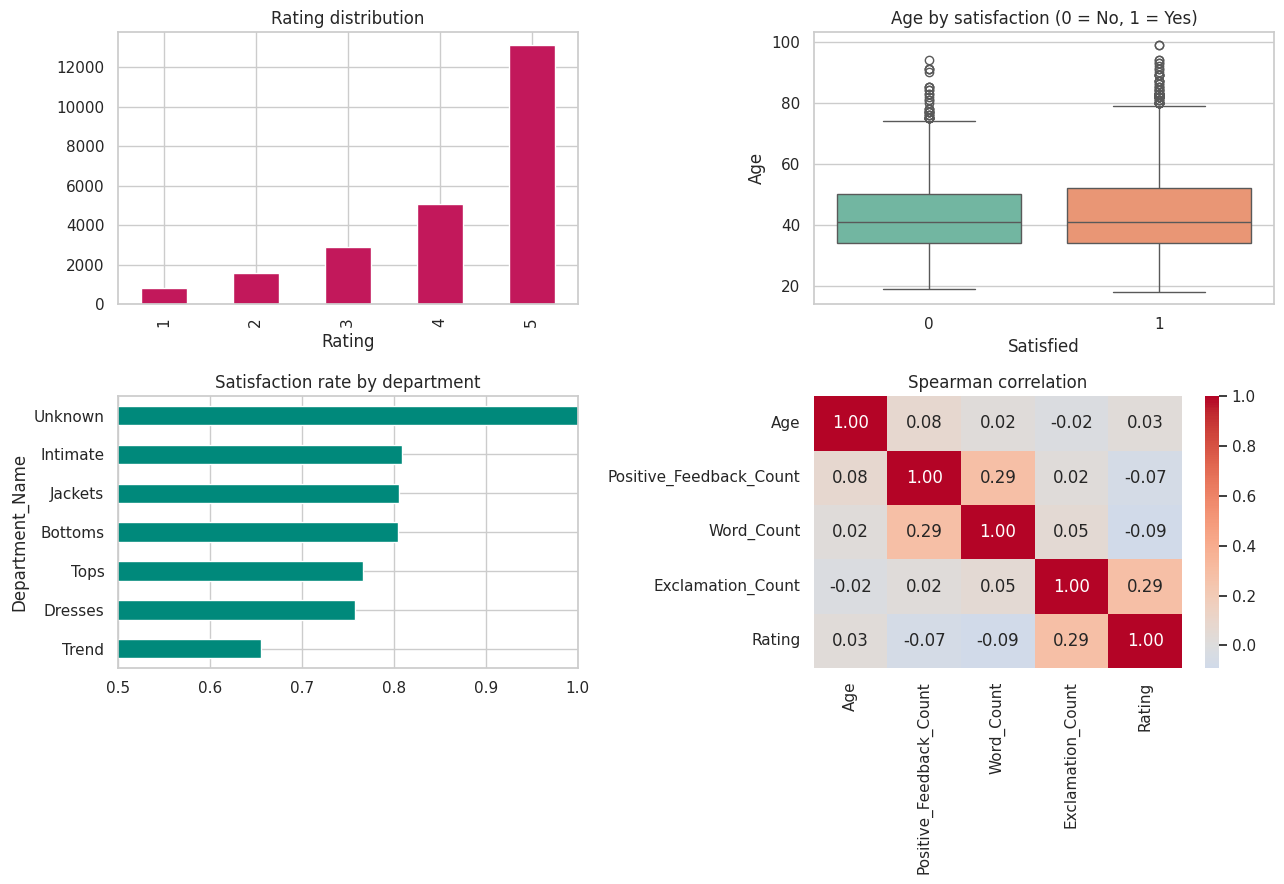

In [ ]:
display(df[["Age", "Positive_Feedback_Count", "Word_Count", "Rating"]].describe().T)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
df["Rating"].value_counts().sort_index().plot(kind="bar", ax=ax[0, 0], color="#c2185b"); ax[0, 0].set_title("Rating distribution")
sns.boxplot(data=df, x="Satisfied", y="Age", ax=ax[0, 1], palette="Set2"); ax[0, 1].set_title("Age by satisfaction (0 = No, 1 = Yes)")
df.groupby("Department_Name")["Satisfied"].mean().sort_values().plot(kind="barh", ax=ax[1, 0], color="#00897b")
ax[1, 0].set_title("Satisfaction rate by department"); ax[1, 0].set_xlim(0.5, 1)
sns.heatmap(df[["Age", "Positive_Feedback_Count", "Word_Count", "Exclamation_Count", "Rating"]].corr("spearman"),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 1]); ax[1, 1].set_title("Spearman correlation")
save_fig("eda_overview")

## 6. Statistical Analysis (Confidence Intervals, Hypothesis Tests, Effect Sizes)

In [ ]:
# 95% Wilson confidence interval for the overall satisfaction rate
k, n = df["Satisfied"].sum(), len(df); z = 1.96; p = k / n
centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
print(f"Satisfaction rate = {p:.3f}  (95% CI {centre - half:.3f} - {centre + half:.3f})\n")

# Numeric variables: Mann-Whitney U test + Cohen's d  (Satisfied vs Not Satisfied)
sat, uns = df[df["Satisfied"] == 1], df[df["Satisfied"] == 0]
def cohens_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)); return (a.mean() - b.mean()) / sp
num_vars = ["Age", "Positive_Feedback_Count", "Word_Count", "Title_Length", "Exclamation_Count", "Question_Count"]
rows = [[v, sat[v].mean(), uns[v].mean(), mannwhitneyu(sat[v], uns[v])[1], cohens_d(sat[v], uns[v])] for v in num_vars]
ht = pd.DataFrame(rows, columns=["Variable", "Mean_Satisfied", "Mean_NotSatisfied", "p_value", "Cohens_d"]).set_index("Variable")
display(ht)

# Categorical variables: Chi-square test + Cramer's V
rows = []
for c in CAT_COLS + ["Age_Group"]:
    tab = pd.crosstab(df[c], df["Satisfied"]); chi, pv, dof, _ = chi2_contingency(tab)
    rows.append([c, chi, pv, np.sqrt(chi / (tab.values.sum() * (min(tab.shape) - 1)))])
chi_df = pd.DataFrame(rows, columns=["Variable", "Chi2", "p_value", "Cramers_V"]).set_index("Variable")
display(chi_df)

# One-way ANOVA: Rating across departments
F, pa = f_oneway(*[g["Rating"].values for _, g in df.groupby("Department_Name")])
print(f"ANOVA (Rating ~ Department): F = {F:.2f}, p = {pa:.2e}")
print("Note: with this many rows almost everything is 'significant' - judge by effect size (|d| < 0.2 negligible, 0.2-0.5 small).")

Satisfaction rate = 0.775  (95% CI 0.770 - 0.780)



,Mean_Satisfied,Mean_NotSatisfied,p_value,Cohens_d
Variable,,,,
Age,43.391,42.541,0.000,0.069
Positive_Feedback_Count,2.332,3.249,0.000,-0.161
Word_Count,57.036,61.681,0.000,-0.154
Title_Length,15.573,17.528,0.000,-0.174
Exclamation_Count,0.955,0.403,0.000,0.408
Question_Count,0.033,0.062,0.000,-0.103


,Chi2,p_value,Cramers_V
Variable,,,
Division_Name,21.685,0.000,0.030
Department_Name,65.097,0.000,0.053
Class_Name,83.111,0.000,0.060
Age_Group,52.280,0.000,0.047


ANOVA (Rating ~ Department): F = 12.99, p = 1.01e-14
Note: with this many rows almost everything is 'significant' - judge by effect size (|d| < 0.2 negligible, 0.2-0.5 small).


## 7. Feature Groups and Train–Test Split
Features are grouped as **Customer** (age), **Product** (division/department/class), **Engagement** (helpful votes), **Text style** (length, punctuation) and **Text content** (TF-IDF words). A stratified 80/20 split is used.

In [ ]:
FEATURE_GROUPS = {
    "Customer":     {"num": ["Age"], "cat": [], "text": False},
    "Product":      {"num": [], "cat": CAT_COLS, "text": False},
    "Engagement":   {"num": ["Log_Positive_Feedback"], "cat": [], "text": False},
    "Text_Style":   {"num": ["Log_Review_Length", "Log_Word_Count", "Title_Length", "Exclamation_Count", "Question_Count", "Has_Title"], "cat": [], "text": False},
    "Text_Content": {"num": [], "cat": [], "text": True},
}
ALL_GROUPS = list(FEATURE_GROUPS)

def make_preprocessor(groups):
    num = sum([FEATURE_GROUPS[g]["num"] for g in groups], []); cat = sum([FEATURE_GROUPS[g]["cat"] for g in groups], [])
    t = []
    if num: t.append(("num", StandardScaler(), num))
    if cat: t.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), cat))
    if any(FEATURE_GROUPS[g]["text"] for g in groups):
        t.append(("txt", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, max_features=2000,
                                         stop_words="english", sublinear_tf=True), "Text"))
    return ColumnTransformer(t)

cols = ["Age"] + CAT_COLS + ["Log_Positive_Feedback", "Log_Review_Length", "Log_Word_Count", "Title_Length",
                             "Exclamation_Count", "Question_Count", "Has_Title", "Text"]
X, y = df[cols], df["Satisfied"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (18772, 12) | Test: (4693, 12)


## 8. Models and Cross-Validation (Stratified 5-Fold)

In [ ]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "Linear SVM": CalibratedClassifierCV(LinearSVC(C=0.1, class_weight="balanced"), cv=3),
        "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=RANDOM_STATE),
    }
pipe = lambda m, groups=ALL_GROUPS: Pipeline([("pre", make_preprocessor(groups)), ("clf", m)])

scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
rows = []
for name, m in get_models().items():
    r = cross_validate(pipe(m), X_train, y_train, cv=cv, scoring=scoring)
    rows.append([name] + [r[f"test_{s}"].mean() for s in scoring] + [r["test_roc_auc"].std()])
cv_results = pd.DataFrame(rows, columns=["Model", "Accuracy", "F1_macro", "ROC_AUC", "PR_AUC", "ROC_AUC_std"]).set_index("Model")
display(cv_results.sort_values("ROC_AUC", ascending=False))
cv_results.to_csv(OUTPUT_DIR / "cross_validation_results.csv")

,Accuracy,F1_macro,ROC_AUC,PR_AUC,ROC_AUC_std
Model,,,,,
Logistic Regression,0.874,0.834,0.937,0.980,0.003
Linear SVM,0.889,0.833,0.936,0.980,0.003
Random Forest,0.876,0.811,0.922,0.975,0.002


## 9. Hyperparameter Tuning

In [ ]:
idx = X_train.sample(6000, random_state=RANDOM_STATE).index         # subsample keeps tuning fast
grids = {"Logistic Regression": {"clf__C": [0.1, 0.3, 1, 3, 10]},
         "Linear SVM": {"clf__estimator__C": [0.03, 0.1, 0.3, 1]}}
tuned, rows = {}, []
for name, g in grids.items():
    gs = GridSearchCV(pipe(get_models()[name]), g, cv=cv, scoring="roc_auc").fit(X_train.loc[idx], y_train.loc[idx])
    tuned[name] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    rows.append([name, tuned[name], gs.best_score_])
display(pd.DataFrame(rows, columns=["Model", "Best_Params", "CV_ROC_AUC"]).set_index("Model"))

,Best_Params,CV_ROC_AUC
Model,,
Logistic Regression,{'C': 1},0.931
Linear SVM,{'estimator__C': 0.3},0.932


## 10. Model Evaluation on the Test Set

,Accuracy,Balanced_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.869,0.853,0.945,0.881,0.912,0.932,0.978
Linear SVM,0.889,0.809,0.907,0.954,0.930,0.932,0.977
Random Forest,0.875,0.786,0.897,0.948,0.922,0.913,0.971


Best model: Logistic Regression


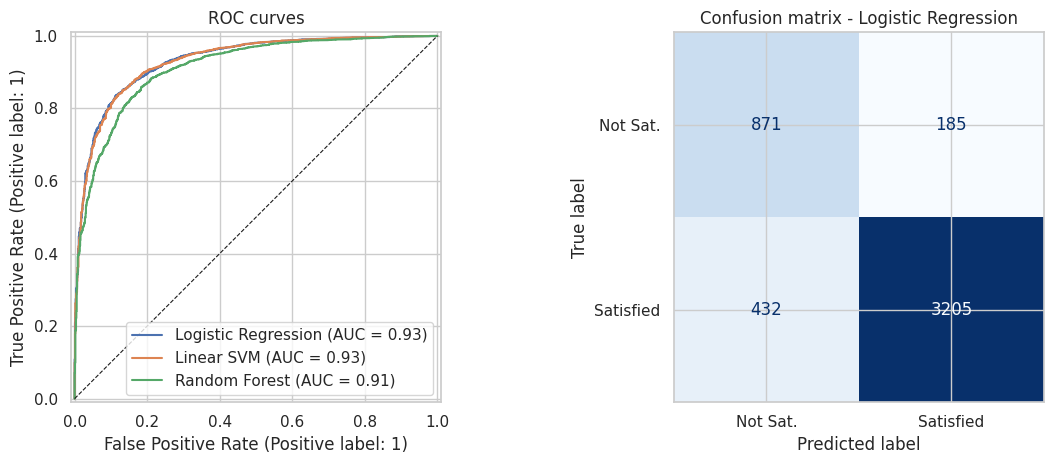

In [ ]:
final_models = get_models()
for name, params in tuned.items():
    final_models[name].set_params(**params)

fitted, rows = {}, {}
for name, m in final_models.items():
    p = pipe(m).fit(X_train, y_train); proba = p.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
    fitted[name] = (p, proba, pred)
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "Balanced_Acc": balanced_accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred), "ROC_AUC": roc_auc_score(y_test, proba),
                  "PR_AUC": average_precision_score(y_test, proba)}
evaluation = pd.DataFrame(rows).T.sort_values("ROC_AUC", ascending=False)
display(evaluation); evaluation.to_csv(OUTPUT_DIR / "test_set_evaluation.csv")
best = evaluation.index[0]; print("Best model:", best)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for name, (_, proba, _) in fitted.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_title("ROC curves")
ConfusionMatrixDisplay.from_predictions(y_test, fitted[best][2], display_labels=["Not Sat.", "Satisfied"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix - {best}")
save_fig("evaluation")

## 11. Feature-Group Experiment (Ablation)
Logistic Regression, 5-fold CV: groups are added one at a time.

,ROC_AUC,F1_macro
Feature_Groups,,
Customer,0.524,0.457
Customer + Product,0.538,0.463
Customer + Product + Engagement,0.567,0.511
Customer + Product + Engagement + Text_Style,0.673,0.556
Customer + Product + Engagement + Text_Style + Text_Content,0.937,0.834


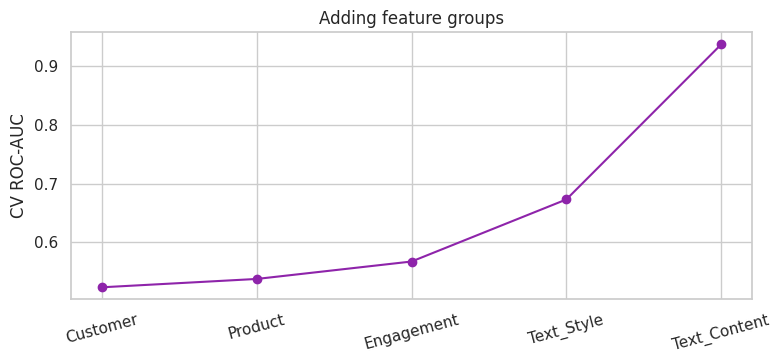

In [ ]:
order = ["Customer", "Product", "Engagement", "Text_Style", "Text_Content"]
rows = []
for i in range(1, len(order) + 1):
    r = cross_validate(pipe(LogisticRegression(max_iter=3000, class_weight="balanced"), order[:i]),
                       X_train, y_train, cv=cv, scoring={"auc": "roc_auc", "f1m": "f1_macro"})
    rows.append([" + ".join(order[:i]), r["test_auc"].mean(), r["test_f1m"].mean()])
ablation = pd.DataFrame(rows, columns=["Feature_Groups", "ROC_AUC", "F1_macro"]).set_index("Feature_Groups")
display(ablation); ablation.to_csv(OUTPUT_DIR / "ablation.csv")

plt.figure(figsize=(8, 3.8))
plt.plot(range(len(ablation)), ablation["ROC_AUC"], marker="o", color="#8e24aa")
plt.xticks(range(len(order)), order, rotation=15); plt.ylabel("CV ROC-AUC"); plt.title("Adding feature groups")
save_fig("ablation")

## 12. Explainability – Which Words Drive Satisfaction?

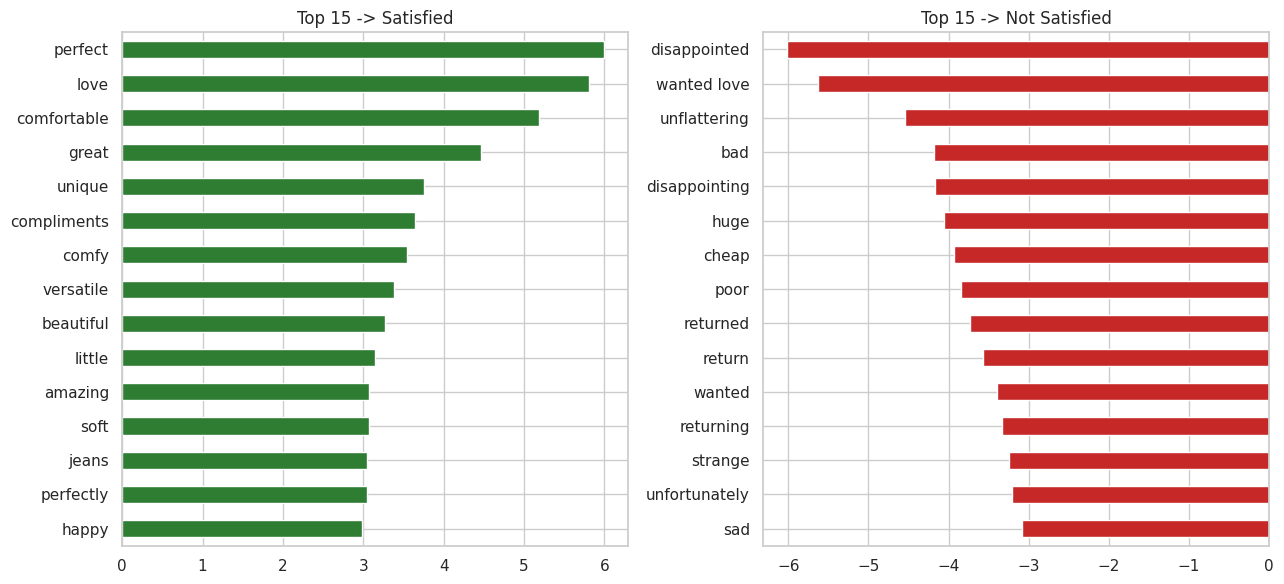

In [ ]:
lr_pipe = fitted["Logistic Regression"][0]
names = pd.Index(lr_pipe.named_steps["pre"].get_feature_names_out()).str.replace(r"^(num|cat|txt)__", "", regex=True)
coef = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=names).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
coef.tail(15).plot(kind="barh", ax=ax[0], color="#2e7d32"); ax[0].set_title("Top 15 -> Satisfied")
coef.head(15)[::-1].plot(kind="barh", ax=ax[1], color="#c62828"); ax[1].set_title("Top 15 -> Not Satisfied")
save_fig("top_words")

## 13. Error Analysis

In [ ]:
proba, pred = fitted[best][1], fitted[best][2]
err = X_test.assign(y_true=y_test.values, proba=proba, y_pred=pred)
err["Error"] = np.where(err.y_true == err.y_pred, "Correct", np.where(err.y_true == 1, "False Negative", "False Positive"))
display(err["Error"].value_counts().to_frame("count").assign(share=lambda d: d["count"] / len(err)))

for label in ["False Positive", "False Negative"]:
    print(f"\n{label} examples:")
    for _, r in err[err.Error == label].sample(3, random_state=RANDOM_STATE).iterrows():
        print(f"  p(satisfied)={r.proba:.2f} | {r.Text[:160]}")

,count,share
Error,,
Correct,4076,0.869
False Negative,432,0.092
False Positive,185,0.039



False Positive examples:
  p(satisfied)=0.67 | Lovely, yet annoying..... . I bought these almost immediately after touching them in store; they were so soft i didn't even need to try them on to know i would 
  p(satisfied)=0.95 | Basic go to . Love the feel and comfort
  p(satisfied)=0.73 | . This top is beautifully made and designed.
material is soft and comfortable however it's very boxy. the details on the side stick out.
i just found it not ver

False Negative examples:
  p(satisfied)=0.13 | . I really wanted to like this since i've purchased previous byron lars dresses and have never not been complimented on them. however, the picture on this one i
  p(satisfied)=0.23 | . Really beautiful dress, too special for me as a guest at a wedding. i think this can be used as a wedding dress in an informal intimate wedding. it is shift d
  p(satisfied)=0.41 | Mosaic masterpiece . I bought the mosaic pattern in a small. the pattern and colors look much better in person. the design and quali

## 14. Key Findings and Conclusion

In [ ]:
top_pos = ", ".join(coef.tail(5).index[::-1]); top_neg = ", ".join(coef.head(5).index)
print(f"""
1. {df['Satisfied'].mean()*100:.1f}% of reviews are Satisfied (imbalanced data -> ROC-AUC / macro-F1 reported).
2. Strongest numeric difference: {ht['Cohens_d'].abs().idxmax()} (Cohen's d = {ht['Cohens_d'][ht['Cohens_d'].abs().idxmax()]:.2f}).
   Categorical associations are weak (largest Cramer's V = {chi_df['Cramers_V'].max():.3f}).
3. Best test model: {best} (ROC-AUC = {evaluation.loc[best, 'ROC_AUC']:.3f}, accuracy = {evaluation.loc[best, 'Accuracy']:.3f}).
4. Review text content gives the largest gain: CV ROC-AUC rises from {ablation['ROC_AUC'].iloc[0]:.3f} (customer only)
   to {ablation['ROC_AUC'].iloc[-1]:.3f} (all feature groups).
5. Words -> Satisfied: {top_pos}
   Words -> Not Satisfied: {top_neg}

Conclusion: customer satisfaction is predicted mainly by what customers write, not by who they are or what
they bought. Limitations: satisfaction is approximated from ratings; reviews are self-selected; one retailer;
results are predictive, not causal. Ethics: data is anonymised - do not re-identify reviewers; use predictions
to support, not replace, human customer-service decisions.
""")


1. 77.5% of reviews are Satisfied (imbalanced data -> ROC-AUC / macro-F1 reported).
2. Strongest numeric difference: Exclamation_Count (Cohen's d = 0.41).
   Categorical associations are weak (largest Cramer's V = 0.060).
3. Best test model: Logistic Regression (ROC-AUC = 0.932, accuracy = 0.869).
4. Review text content gives the largest gain: CV ROC-AUC rises from 0.524 (customer only)
   to 0.937 (all feature groups).
5. Words -> Satisfied: perfect, love, comfortable, great, unique
   Words -> Not Satisfied: disappointed, wanted love, unflattering, bad, disappointing

Conclusion: customer satisfaction is predicted mainly by what customers write, not by who they are or what
they bought. Limitations: satisfaction is approximated from ratings; reviews are self-selected; one retailer;
results are predictive, not causal. Ethics: data is anonymised - do not re-identify reviewers; use predictions
to support, not replace, human customer-service decisions.

